<a href="https://colab.research.google.com/github/a-gidding/STAT-7110-Quality-Control/blob/main/Giddings_stat_7110_hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "a-gidding"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive to today's lecture (update the folder name to match your repo):

setwd("/content/STAT-7110-Quality-Control/Assignments/HW3")

### go ahead and run the libraries necessary for this assignment ###
install.packages("qcc")
library(tidyverse)
library(readxl)
library(qcc)
library(dplyr)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



## Homework 3 - Analysis Using the $p$, $np$, $c$, and $u$ Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 30, 2026 via D2L**

## Instructions:

Ravi's Comics and Games is a local comic book and tabletop game shop that receives weekly new-release shipments from a regional distributor. Ravi's customers, especially the collectors chasing near-mint copies, have started complaining more often about comics arriving with scratched or folded covers, and Ravi has noticed it's starting to hurt sales of his higher-end back issues too. He's asked your quality control team to help him figure out how bad the problem really is, whether it's getting better or worse, and who -- the distributor, or his own shop -- is responsible.

Your team decides to look at this two different ways. First, every comic in a week's shipment gets a quick pass/fail condition check as staff unbox and shelve it (any visible scratch, crease, or fold on the cover marks it nonconforming). Because the number of comics in a shipment varies week to week depending on the new-release schedule, your team tracks both the **rate** of nonconforming comics (useful for spotting trends) and the **raw count** (useful when Ravi calls the distributor's account representative, who thinks in terms of "how many books," not percentages).

Second, your team recognizes that a single comic can have more than one distinct defect on it -- a scratch on the front cover **and** a folded corner on the back, for example -- so a simple pass/fail check doesn't capture the full severity of the damage. To get a fuller picture, staff also perform a more detailed defect count each week, counting every individual scratch, fold, or dent they find (not just how many comics have at least one). This detailed count is done on two separate parts of the shop: a **fixed** sample of 5 boxes pulled from the new-release shipment every week, and a **variable** number of already-shelved back-issue boxes, inspected whenever staff have the time.

## Key Specifications

| Quantity | Value |
|---|---|
| Nonconforming definition (Datasets A) | Any visible scratch, crease, or fold on the cover |
| Nonconformity definition (Datasets B & C) | Each individual scratch, fold, or dent found (a comic may have more than one) |
| Dataset A: Shipment Condition, Phase I weeks (m) | 25 weeks, variable shipment size |
| Dataset A: Shipment Condition, Phase II weeks (m) | 20 weeks, variable shipment size |
| Dataset B: New-Release Defect Counts, weeks (m) | 25 weeks, fixed sample of 5 boxes/week |
| Dataset C: Back-Issue Defect Counts, weeks (m) | 25 weeks, variable number of boxes/week |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

This analysis is to check the quality of the comic books at Ravi's Comics and Games. Specifically, it is to determine if comic books are already damaged upon arrival to the bookstore or wehther the comics are being damaged after being inventoried.

### Q2: Ravi's team is monitoring two distinct quality characteristics here: a pass/fail condition check, and a detailed defect count. For each, classify the type of attribute data being collected, and briefly explain how this differs from the continuous, normally-distributed data used in your previous two homeworks.

For the pass/fail condition check, it is a binary attribute because there are only two outcomes. Either the comic book is in good condition or it is not. This is different from our continuous, normally distributed data because we can't have part of a condition/damage. Either the book is in good condition or it is not and the rate should not be normal since we do not expect an equal or even distrubition.

For the detailed defect count, it is a

### Q3: For the pass/fail data (Dataset A), what practical factor determines whether you should build a $p$ chart or an $np$ chart? For the detailed defect-count data (Datasets B and C), what practical factor determines whether you should build a $c$ chart or a $u$ chart?

For the pass/fail data, the practical factor would be how it is measured. Since it is measured with only a pass/fail or binary atatribute, it would be best to use an np chart.

For the detailed defect-count, the practical factor that determines which chart to build is how the defect count is measured and the number of samples its across. Since our defect number is for each shipment, we will need to run a u chart.

## Analyze

### Q4: Read the Phase I Shipment Condition data (Dataset A) into R. Construct a Phase I $p$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

After running the initial p chart, we can see that week 14 is out of control. The reason that it is plotting as out of control is due to the fact that close to 50% of the shipment had deformities/damage.

After removing week 14, we can see that our chart shows statistical control.

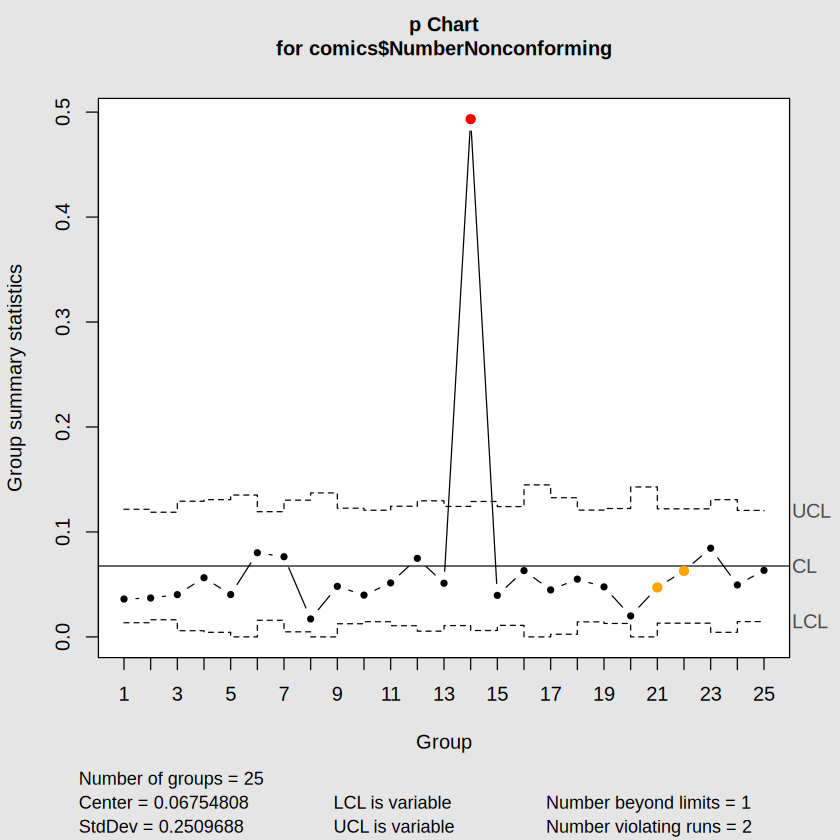

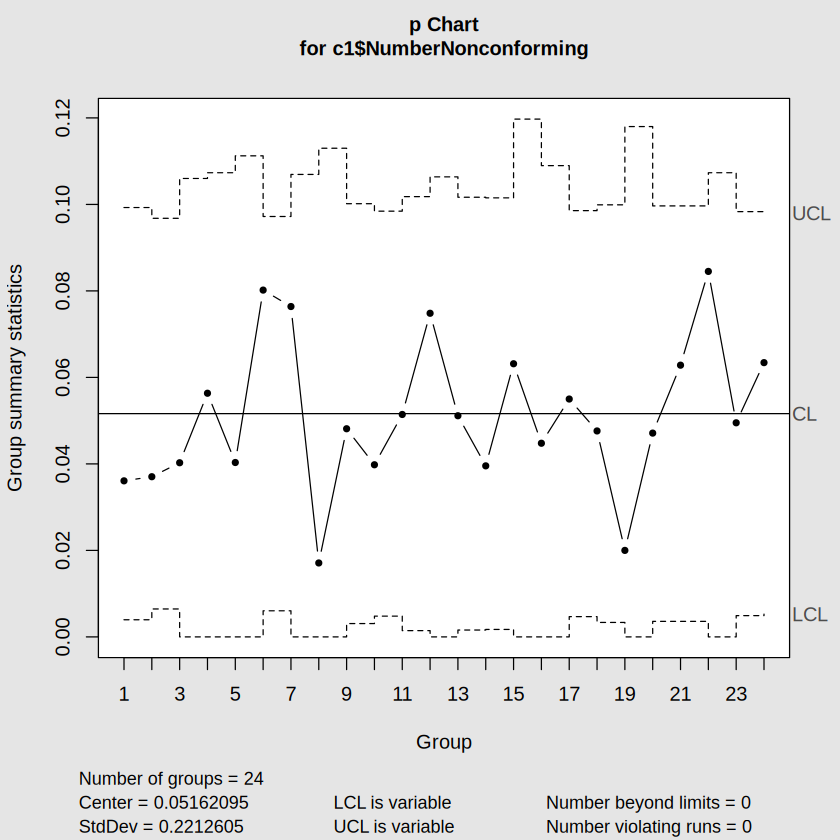

In [2]:
## Q4 Code ##

## read in the excel ##
comics <- read_excel("RavisComics_ShipmentCondition_PhaseI.xlsx")

## run the p chart ##
comicp1_chart <- qcc(comics$`NumberNonconforming`,
                    type="p",
                    sizes=comics$`TotalComics`,
                    plot=TRUE)

### we can see that point number 14 is out of control. We need to omit it using the code shown in class and replot the chart ###
ooc_points <- comicp1_chart$violations$beyond.limits

c1 <- comics[-ooc_points,]

c1p1_chart1 <- qcc(c1$`NumberNonconforming`,
                  type="p",sizes=c1$`TotalComics`,
                  plot=TRUE)

### Q5: Repeat the analysis in Q4, this time constructing an $np$ chart on the same data. Do your conclusions about which week(s) are out of control change? Which chart do you think would be easier to explain to the distributor's account representative, and why?

After running our np chart, we can see that week 14 is our out of control point. This appears to be due to the fact that over 60 comics in the shipment arrived damaged/nonconforming.

It is easier to explain this chart to the distributor's account representative due to the fact that it shows actual numbers rather than assuming that the viewer can infer what is being said on the y axis.

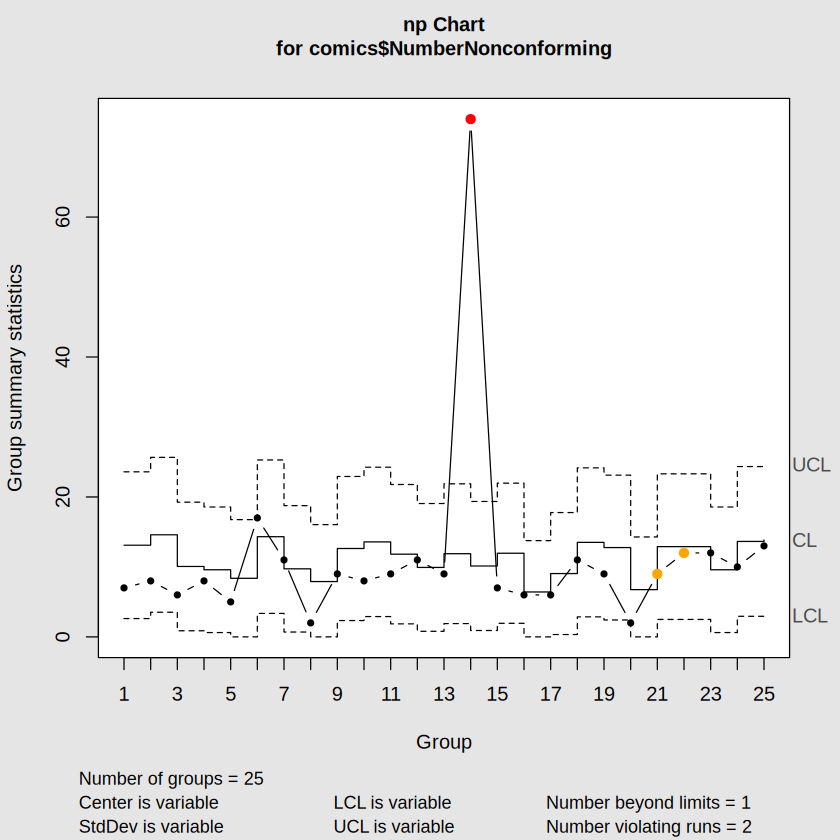

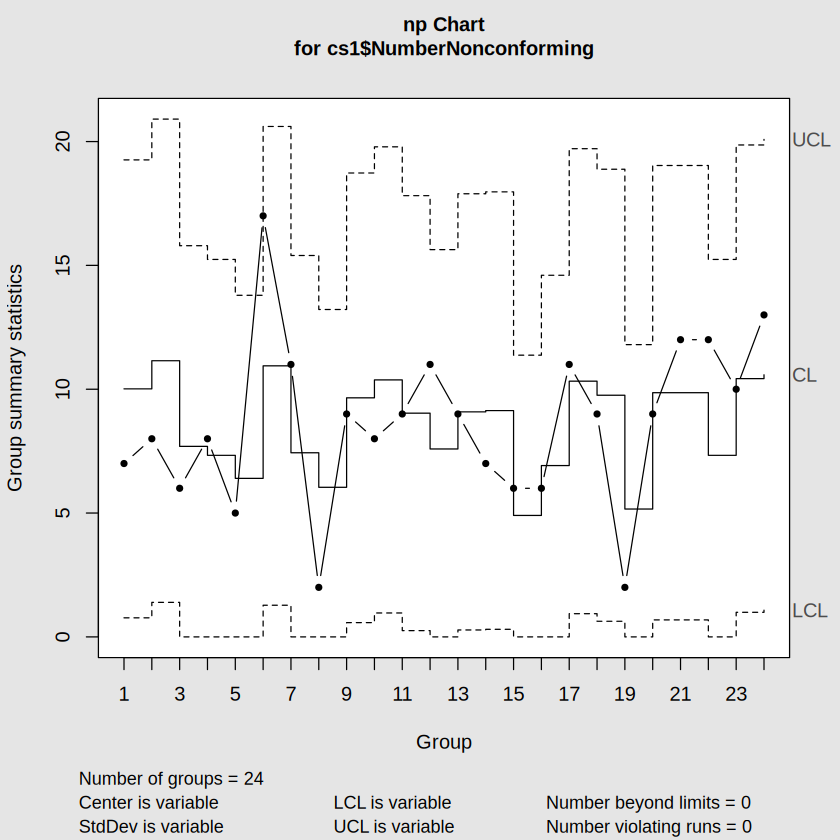

In [4]:
## Q5 Code ##

## now we need to run the np chart instead of the p chart ##
comicsnp1_chart <- qcc(comics$`NumberNonconforming`,
                    type="np",
                    sizes=comics$`TotalComics`,
                    plot=TRUE)

## we can see that week 14 is out of control ##
ooc_points <- comicsnp1_chart$violations$beyond.limits

cs1 <- comics[-ooc_points,]

cs1p1_chart1 <- qcc(cs1$`NumberNonconforming`,
                  type="np",
                  sizes=cs1$`TotalComics`,
                  plot=TRUE)

### Q6: Using your finalized Phase I estimate of $\bar{p}$, report the center line and control limits you will carry forward into Phase II.

The upper control limit will be 19 and our lower control limit will be approximiately 1. We rounded to the nearest whole number for these limits as we can't have part of a damage for our dependent variable.
Our p bar is...

In [15]:
## Q6 Code ##

cs1p1_chart1$limits

uclp <- cs1p1_chart1$limits[1,2]
lclp <- cs1p1_chart1$limits[1,1]
pbar <- cs1p1_chart1$center


,LCL,UCL
,0.7690558,19.25987
,1.3945672,20.90568
,0.0000000,15.79401
,0.0000000,15.24005
,0.0000000,13.79256
,1.2788347,20.60845
,0.0000000,15.39880
,0.0000000,13.21955
,0.5760402,18.73019
,0.9650819,19.78654


## Improve

### Q7: After seeing your Phase I results, Ravi calls the distributor, who agrees to add cardboard stiffeners to every shipping box going forward. Briefly explain why it would not be appropriate to use your *original* (uncleaned) Phase I control limits, rather than the finalized limits from Q6, to judge whether this packaging fix actually worked.

After seeing our phase 1 results, it is important that we use our cleaned control limits because if we were to use our original limits, it would include the uncleaned, out of control points that we were faced with initially. The cleaned data provides us the opportunity to determine whethere there has been improvement to keep the system in control based on what the limits and p bar SHOULD look like.

## Control

### Q8: Read the Phase II Shipment Condition data into R. Using your finalized Phase I center line and control limits from Q6, construct the Phase II $p$ chart. Do any weeks plot outside the control limits? Does this support the conclusion that the packaging fix worked?

The plotting for my p-chart is not appearing accurately. With that being said, this could be due to the significantly low number of damaged comics despite the large proportion size of total comics. This would support that the packaging fix worked, but it would be best to attempt a different chart type to see if it is truly supported.

Warning message in statistics - center:
“longer object length is not a multiple of shorter object length”


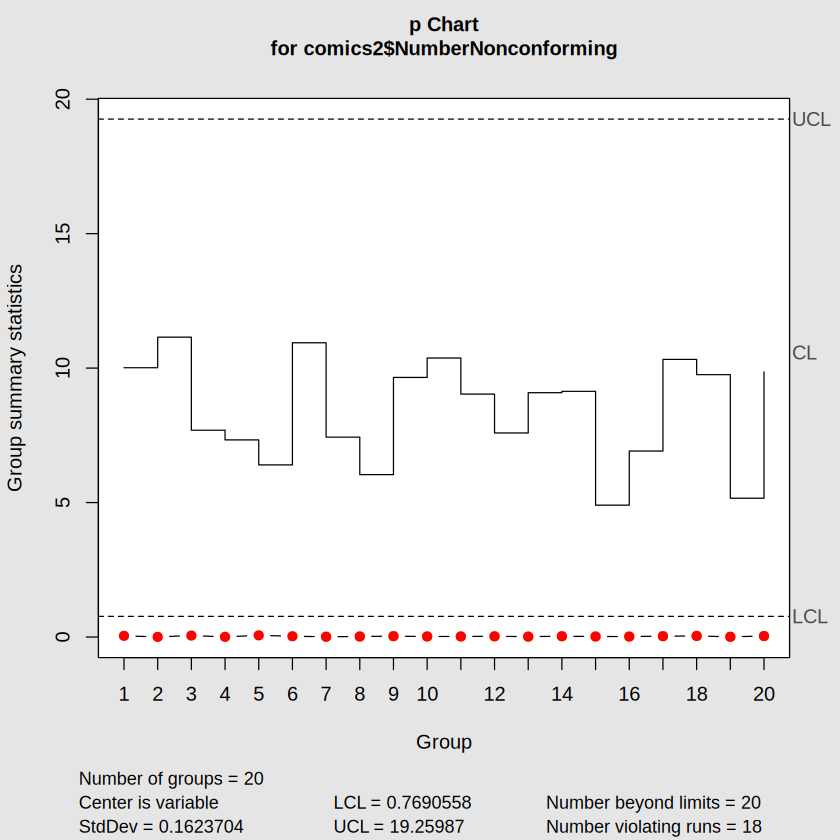

In [14]:
## Q8 Code ##

## read in the excel ##
comics2 <- read_excel("RavisComics_ShipmentCondition_PhaseII.xlsx")

## create p chart using the Phase 1 limits and center that was previously calculated ##
comics2_chartp2 <- qcc(comics2$`NumberNonconforming`,
                   type="p",sizes=comics2$`TotalComics`,
                   limits = c(lclp,uclp),
                   center = pbar,
                   plot=TRUE)

### Q9: Repeat Q8 using an $np$ chart instead. Is your conclusion consistent with Q8?

Warning message in statistics - center:
“longer object length is not a multiple of shorter object length”


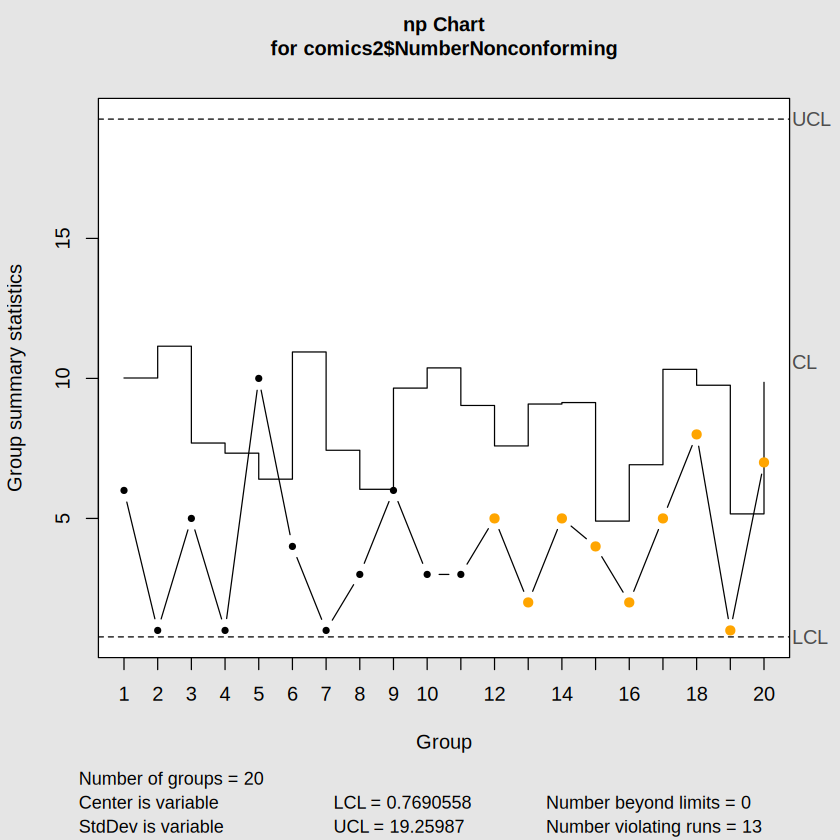

In [10]:
## Q9 Code ##

## create p chart using the Phase 1 limits and center that was previously calculated ##
comics_chartp2 <- qcc(comics2$`NumberNonconforming`,
                   type="np",sizes=comics2$`TotalComics`,
                   limits = c(lclp,uclp),
                   center = pbar,
                   plot=TRUE)

### Q10: Read the New-Release Defect Counts data (Dataset B) into R. Construct a $c$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

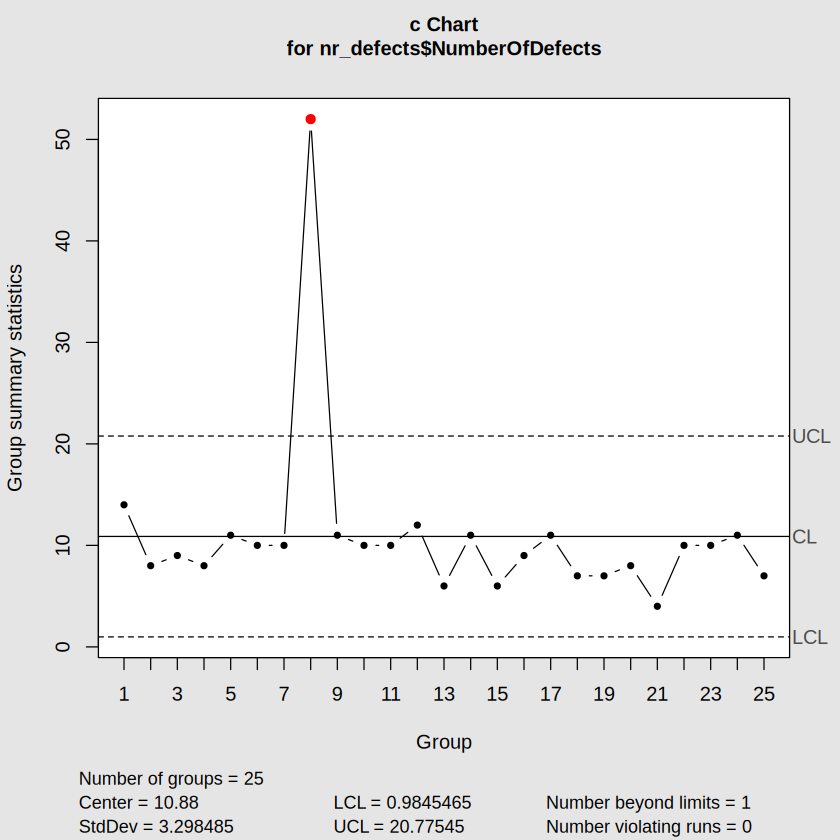

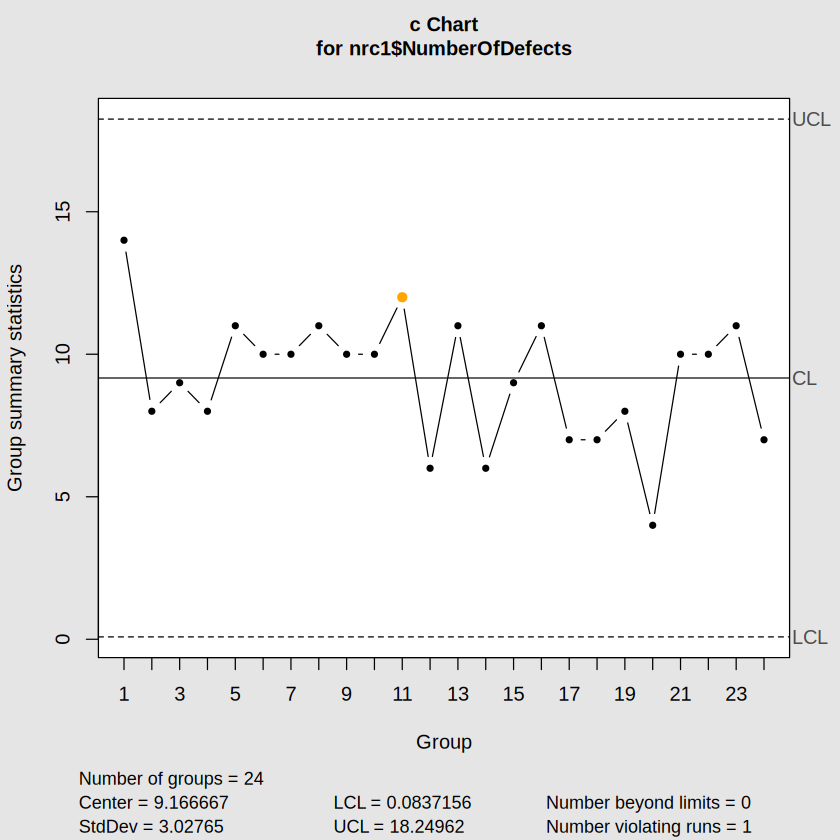

In [21]:
## Q10 Code ##

nr_defects <- read_excel("RavisComics_NewReleaseDefectCounts.xlsx")

## Phase 1 to get the control limits ##
nrc_chart <- qcc(nr_defects$`NumberOfDefects`,
                          type="c",plot=T)

## remove OOC Points ##

ooc_points <- nrc_chart$violations$beyond.limits

nrc1 <- nr_defects[-ooc_points,]

nrc_chart1 <- qcc(nrc1$`NumberOfDefects`,
                           type="c",plot=T)

## get the control limits and apply to P2, if necessary ##
uclc <- nrc_chart1$limits[2]
lclc <- nrc_chart1$limits[1]
cl <- nrc_chart1$center


### Q11: Using your finalized $c$ chart, report $\bar{c}$ and the control limits. In 1-2 sentences, explain what this chart tells Ravi that the Q4-Q9 pass/fail analysis could not.

For the finalized c chart, we can see that the lower control limit is <1 (so... 0) and the upper control limit is 18. Our c bar is... With this information, we are able to get an exact number of deformity counts that would be out of the ordinary, which is something that was not offered with a pass or fail. This gives us a better idea of what the extent of the damage could actually be on average/per shipment seeing as the more severe the damage is, the less likely Ravi is to be able to sell comics at all.

In [23]:
## Q11 Code ##

nrc_chart1$limits

uclc <- nrc_chart1$limits[2]
lclc <- nrc_chart1$limits[1]
cl <- nrc_chart1$center

,LCL,UCL
,0.0837156,18.24962


### Q12: Read the Back-Issue Defect Counts data (Dataset C) into R. Construct a $u$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

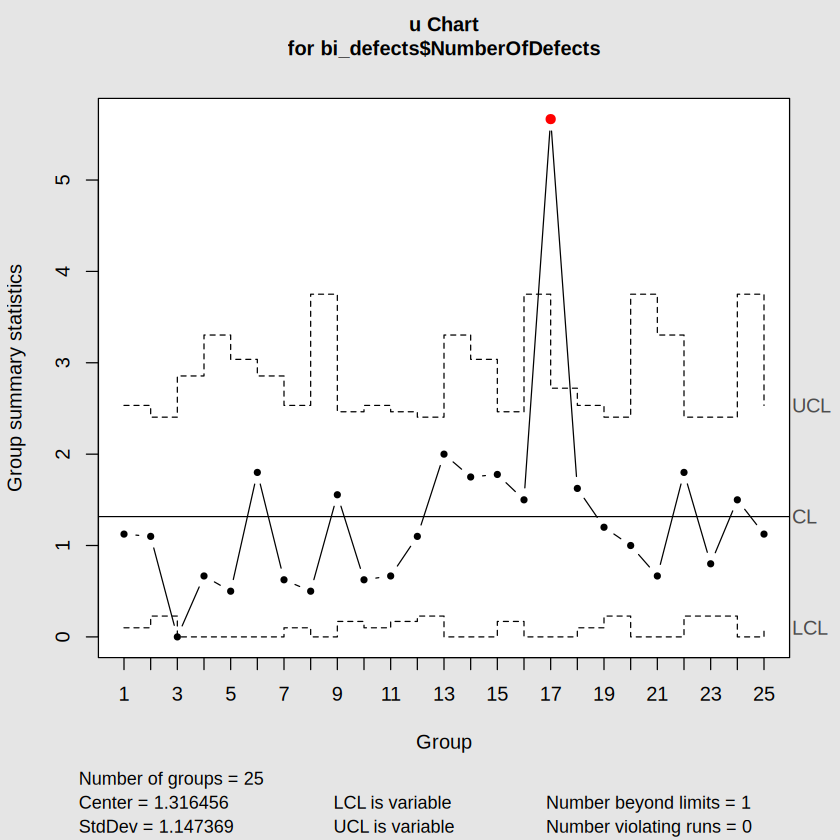

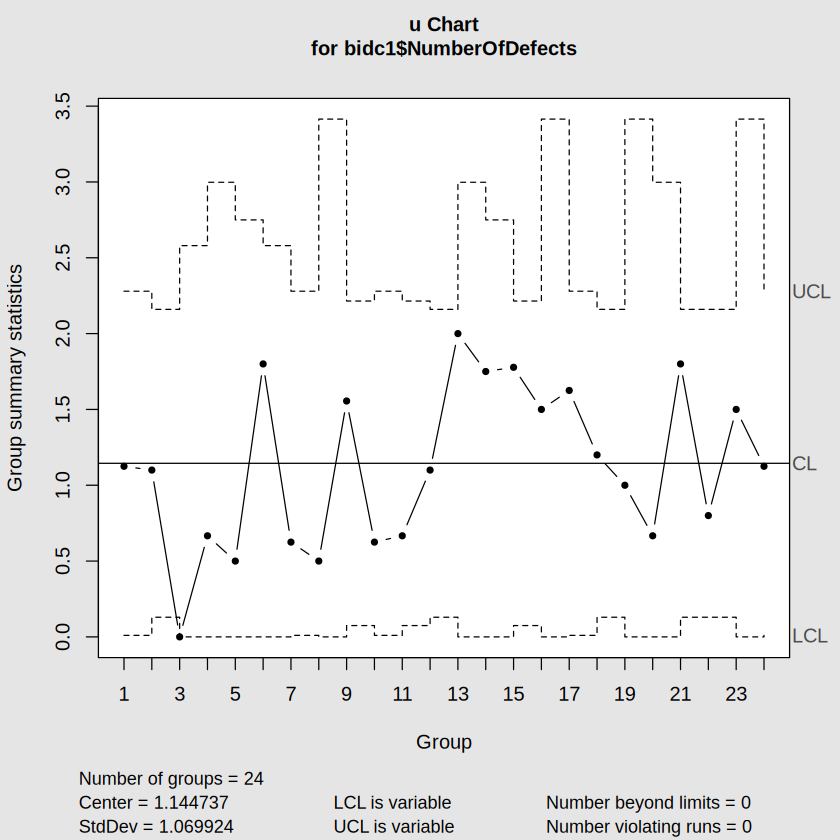

In [26]:
## Q12 Code ##

bi_defects <- read_xlsx("RavisComics_BackIssueDefectCounts.xlsx")

## Plot U Chart ##

bid_chart <- qcc(bi_defects$`NumberOfDefects`,
                     type="u",sizes=bi_defects$`BoxesInspected`)
## Remove Out of control points ##
ooc_points <- bid_chart$violations$beyond.limits

bidc1 <- bi_defects[-ooc_points,]

## replot ##

bid_chart1 <- qcc(bidc1$`NumberOfDefects`,
                           type="u",sizes=bidc1$`BoxesInspected`)

### Q13: Suppose you tried to build a $c$ chart on the Back-Issue Defect Counts data instead of a $u$ chart. Why would this not be an appropriate choice, given how the data were collected?

If we attempted to build a c chart rather than a u chart, we wouldn't have a true understanding of what the damage looked like proportionally. For our c chart, we would need the full number of comics rather than just the number of boxes meaning that we have more variable sample sizes across time that a c chart wouldn't be able to handle well. The c chart was more realistic for the other data sample since we only examined 5 boxes every week versus the entire varying shipment on a week to week basis like in the new releases data.

### Q14: Provide an overview of your results that Ravi can use the next time he calls the distributor's account representative. Citing specific evidence from your $p$/$np$ analysis **and** your $c$/$u$ analysis, which parts of the damage problem look like they're the distributor's responsibility, and which parts (if any) look more like an internal, in-shop handling issue?

Based on my results, it does appear to be a distrubtor issue rather than a store issue. Due my phase one analysis, I was able to see that the amount of comics that were damaged on a shipment to shipment basis varied as did where the damage was located. What clued me in to realizing this was a distributor issue is the fact that after adding the cardboard stiffeners, less comics were damaged upon arrival and stocking. We had a singular outlier where there were 5 comics that were damaged as our maximum in comparison to our initial analysis where out of over 100 comics, 70 were damaged. Now, after adding the stiffeners, there is more potential that damage that is occurring is from stocking in house, but this could require further analysis of customer complaints when shopping. I would also say considering the violation indicators in my model, there is a chance that some of this damage is occurring during the later/busier weeks, which maeans that employees may be rushing to complete the stocking of comics and unintentionally damaging them in the process. However, until further testing is completed, this is speculative, but certainly something we could continue to track.